# Data encoding and the expressive power of variational quantum models — a reproduction

**Paper:** Schuld, Sweke, Meyer, *The effect of data encoding on the expressive power of variational quantum machine learning models*, Phys. Rev. A 103, 032430 (2021), [arXiv:2008.08605](https://arxiv.org/abs/2008.08605).

This notebook is the reproduction written as a scientific argument. It starts from the paper's claim, shows the evidence, tests credible alternative explanations, and ends with an exact statement of what did and did not reproduce.

**How to read it.**
- Cells marked *live* run here, on CPU, in a few seconds each (whole notebook: a few minutes).
- Cells marked *stored* load results from `results/*.json`, produced by the full runs documented in `LOG.md` (6 seeds, up to 20, many protocols). The source run of every stored number is named in its cell.
- After every major result you will find four labelled lines: **Observation**, **Inference**, **Remaining uncertainty**, **Claim impact**.

**Contents.** 1 Claim · 2 Data and protocol · 3 Mathematics · 4 Sanity checks · 5 Model walkthrough · 6 Live fits · 7 Headline result · 8 Fair baselines · 9 Controls · 10 Robustness · 11 Photonic extension · 12 Conclusion.

## 1. The paper's claim, as a falsifiable question

A quantum model $f(x)=\langle 0|U(x)^\dagger M\,U(x)|0\rangle$ whose data enters through encoding gates $e^{-ixH}$ can be written as a Fourier-type sum

$$f(x)=\sum_{\omega\in\Omega}c_\omega e^{i\omega x},\qquad \Omega=\{\Lambda_k-\Lambda_j\},\quad \Lambda_j=\lambda_{j_1}+\dots+\lambda_{j_L},$$

where the $\lambda$ are eigenvalues of $H$. The paper then claims:

| ID | Claim | Where tested here |
|---|---|---|
| C1 | The spectrum depends only on the eigenvalues of the encoding generator; the rest of the circuit sets the coefficients | §4 (live), §11 |
| C2/C3 | One Pauli encoding gives a single sine; a frequency mismatch cannot be fit | §6 (live), §7 |
| C4/C5 | Repeating the encoding $r$ times, serially or in parallel, gives degree $r$; the degree-5 target is fit "almost perfectly" at $r=5$ (Fig. 4) | §6, §7, §8–§10 |
| C9 | With arbitrary unitaries and observable, such models are universal | §11 |

**Research question.** Do these claims hold when reproduced with several seeds and a fair control, and which parts of the paper's *explanation* survive?

**What would weaken the claim.**
- A spectrum with frequencies outside the prediction (C1, C4).
- A degree-$r$ model failing to fit a degree-$r$ target that a matched classical model fits (expressivity claim).
- A fit that works only under a narrow training protocol (the paper's training figure would then be anecdotal).

Types of evidence used: *faithful reproduction* (paper's circuits and protocol), *controls* (closed-form floor, matched classical model), *robustness* (seeds, protocols), and *extension* (photonic adaptation, labelled as such).

In [1]:
import sys, json, time, logging, warnings
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
logging.disable(logging.CRITICAL)          # silence per-step training logs in the notebook

PAPER_DIR = Path.cwd()
assert (PAPER_DIR / "lib" / "runner.py").exists(), "run this notebook from papers/data_encoding_expressivity"
REPO_ROOT = PAPER_DIR.parents[1]
for root in (REPO_ROOT, PAPER_DIR):
    if str(root) not in sys.path:
        sys.path.insert(0, str(root))

# Reusable implementation lives in lib/; the notebook only configures and interprets.
from lib.data import build_dataset, evaluate_target
from lib.baselines import least_squares_oracle
from lib.fourier import fourier_coefficients, periodic_grid, spectrum_support, predicted_spectrum
from lib.training import build_fit_model, train_fit_model, model_frequencies, count_parameters
from lib.circuits import SerialPauliModel, ParallelPauliModel

DTYPE = torch.float64
DEVICE = torch.device("cpu")
RESULTS = PAPER_DIR / "results"
NOTEBOOK_START = time.perf_counter()
print("torch", torch.__version__, "| numpy", np.__version__, "| device", DEVICE)

torch 2.4.1 | numpy 2.3.5 | device cpu


## 2. Data, metric and evaluation protocol

**Data.** The paper uses no dataset. Its "data" are closed-form target Fourier series sampled on a grid. The grid, initialisation, optimiser and step count are *not* stated in the paper for Fig. 3; they are taken from the authors' released notebook (`linspace(-6, 6, 70)`, angles $U[0,2\pi)$, Adam with learning rate 0.3, mini-batches of 25 drawn with replacement, 200 steps). Targets:

- **Fig. 3:** $c_0=0.1,\ c_n=0.15-0.15i$, degree 1 (rows a, b) or 2 (row c).
- **Fig. 4:** $c_0=0,\ c_n=0.05-0.05i$, degree 5. The caption writes $e^{2inx}$, but the published panel matches input scaling 1 (the notebook's), which we use as primary (see §9 for the check).

**Metric.** Mean squared error on the full 70-point grid (plain MSE; the authors' notebook uses $0.5\cdot$MSE, which does not matter to Adam apart from its $\epsilon$). There is **no train/test split**: the paper's task is to fit a known function, so "trainability on the training grid" is the quantity measured. No hyperparameter or model selection is made on any evaluation data, and no result below is selected; every case and seed is shown.

**Protocols.** P0 is the paper's (Adam, lr 0.3, batch 25, 200 steps). P1–P5 are *non-paper* protocols (full batch; lr 0.3/0.05/0.01 with Adam; cosine-decayed Adam; L-BFGS), used only as controls.

**Seeds.** Stored results use 6 seeds (0–4 and 42) or 20; live cells use 3 for speed, and say so.

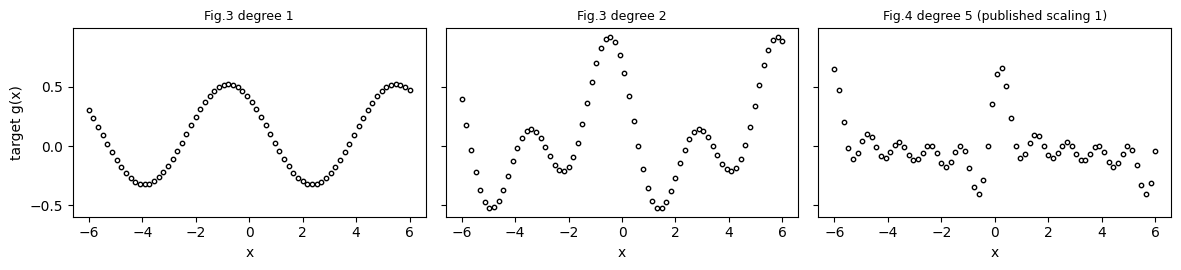

target                                    deg 1  deg 2  deg 3  deg 4  deg 5  deg 6
Fig.3 degree 1                           2.1e-32 6.6e-33 4.4e-31 3.6e-31 1.4e-31 9.8e-32
Fig.3 degree 2                           9.0e-02 5.6e-32 3.9e-31 6.2e-32 3.8e-31 1.5e-31
Fig.4 degree 5 (published scaling 1)     3.6e-02 2.8e-02 1.9e-02 9.9e-03 1.9e-32 2.0e-32


In [2]:
GRID = {"start": -6.0, "stop": 6.0, "num": 70}
def target(c0, coeffs, sign, scaling):
    return {"c0": c0, "coefficients": [{"re": c.real, "im": c.imag} for c in coeffs], "sign": sign, "scaling": scaling}

TARGETS = {
    "Fig.3 degree 1": target(0.1, [0.15 - 0.15j], -1, 1.0),
    "Fig.3 degree 2": target(0.1, [0.15 - 0.15j] * 2, -1, 1.0),
    "Fig.4 degree 5 (published scaling 1)": target(0.0, [0.05 - 0.05j] * 5, +1, 1.0),
}
x_grid, _ = build_dataset({"grid": GRID, "target": TARGETS["Fig.4 degree 5 (published scaling 1)"]}, DTYPE)

fig, ax = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
for a, (name, tgt) in zip(ax, TARGETS.items()):
    y = evaluate_target(x_grid, tgt)
    a.scatter(x_grid, y, s=10, facecolor="white", edgecolor="black"); a.set_title(name, fontsize=9); a.set_xlabel("x")
ax[0].set_ylabel("target g(x)"); plt.tight_layout(); plt.show()

# B1: the closed-form best fit over a model's exact frequency set = the lowest MSE any model of that class can reach.
rows = []
for name, tgt in TARGETS.items():
    y = evaluate_target(x_grid, tgt).numpy()
    for degree in (1, 2, 3, 4, 5, 6):
        rows.append((name, degree, least_squares_oracle(x_grid.numpy(), y, list(range(1, degree + 1)), 1.0)["mse"]))
print(f"{'target':40s}" + "".join(f"  deg {d}" for d in range(1, 7)))
for name in TARGETS:
    print(f"{name:40s}" + "".join(f" {m:7.1e}" for n, d, m in rows if n == name))

**Observation.** The B1 floor (best achievable MSE for a model with frequencies $1..D$) is positive below the target's degree and numerically zero ($\sim10^{-32}$) at or above it: the degree-1 and degree-2 Fig. 3 targets are exactly representable only from their own degree up, and the degree-5 Fig. 4 target only from $D=5$.

**Inference.** The paper's expressivity claim is therefore *checkable without training*: a model of degree $D<5$ cannot fit Fig. 4 better than its B1 value, whatever the optimiser. Every later comparison in the notebook is judged against this floor.

**Remaining uncertainty.** B1 assumes free coefficients; a real circuit can reach less (§11 shows an example).

**Claim impact.** None yet; this sets the yardstick.

## 3. The minimum mathematics

Diagonalise the encoding generator, $H=V^\dagger\Sigma V$, and absorb $V$ into the trainable blocks. With $L$ encoding layers, the frequencies are all differences of sums of $L$ eigenvalues:

$$\Omega=\{\lambda_{k_1}+\dots+\lambda_{k_L}-\lambda_{j_1}-\dots-\lambda_{j_L}\}.$$

- **One Pauli encoding** ($H=\sigma/2$, eigenvalues $\pm\frac12$, $L=1$): $\Omega=\{-1,0,1\}$, so $f(x)=A\sin(x+B)+C$, whatever $W$ and $M$ are.
- **$r$ serial repetitions** ($L=r$) or **$r$ parallel qubits** ($H=\tfrac12\sum_q\sigma^{(q)}$, $L=1$): both give $\Omega=\{-r,\dots,r\}$.
- **Size bound:** $K=(|\Omega|-1)/2\le d^{2L}/2-1$ (valid but loose; a tighter count is $K\le m(m-1)/2$ with $m=d^L$ distinct eigenvalue sums).
- **Coefficients:** $c_\omega$ depends on the whole circuit and the observable $M$.
- **Universality:** if $\Omega$ eventually contains every integer and the unitaries and $M$ are arbitrary, any $L^2$ function can be approximated.

Everything in the first three bullets can be verified exactly; §4 does so.

## 4. Known-answer sanity checks (live)

Three checks before trusting any fit.

1. **Known answer:** an encoding $RX(x)$ with no trainable blocks gives $\langle Z\rangle=\cos x$ exactly.
2. **Predicted spectrum:** from the generator's eigenvalues, compute $\Omega$, then compare with the FFT support of random circuits (serial and parallel).
3. **Gradients:** autograd against parameter shift (done in `tests/test_circuits.py`; shown there, not repeated).

In [3]:
# Check 1: known-answer model.
from lib.circuits import ParallelPauliModel
bare = ParallelPauliModel(3, 1.0, "none", 0, "z0", DTYPE)
xs = torch.linspace(-6, 6, 25, dtype=DTYPE)
with torch.no_grad():
    err = (bare(xs) - torch.cos(xs)).abs().max().item()
print(f"RX(x) encoding, no trainable blocks: max |<Z> - cos x| = {err:.1e}")
assert err < 1e-12

# Check 2: predicted spectrum vs FFT support of random circuits, serial and parallel.
def fft_support(values, tol=1e-9):
    freqs, coeffs = fourier_coefficients(values)
    return set(spectrum_support(freqs, coeffs, tol))

print(f"{'r':>2s} {'predicted':>22s}  {'serial observed':>22s}  {'parallel observed':>22s}  stray coefficient")
for r in range(1, 6):
    predicted = [int(round(v)) for v in predicted_spectrum([-0.5, 0.5], r)]
    grid = torch.tensor(periodic_grid(4 * r + 8), dtype=DTYPE)
    observed, stray = {}, 0.0
    for layout in ("serial", "parallel"):
        union = set()
        for seed in range(3):
            model = (SerialPauliModel(r, 1.0, "z0", DTYPE) if layout == "serial"
                     else ParallelPauliModel(r, 1.0, "strongly", 3, "z0", DTYPE))
            model.reset_parameters(torch.Generator().manual_seed(seed), 2 * np.pi)
            with torch.no_grad():
                values = model(grid).numpy()
            union |= fft_support(values)
            f, c = fourier_coefficients(values)
            stray = max(stray, float(np.abs(c[~np.isin(f, predicted)]).max()))
        observed[layout] = sorted(union)
    ok = all(observed[l] == predicted for l in observed)
    print(f"{r:2d} {str((predicted[0], predicted[-1])):>22s}  {str((observed['serial'][0], observed['serial'][-1])):>22s}  "
          f"{str((observed['parallel'][0], observed['parallel'][-1])):>22s}  {stray:.1e}  {'OK' if ok else 'MISMATCH'}")
    assert ok

RX(x) encoding, no trainable blocks: max |<Z> - cos x| = 2.2e-16
 r              predicted         serial observed       parallel observed  stray coefficient
 1                (-1, 1)                 (-1, 1)                 (-1, 1)  1.5e-16  OK
 2                (-2, 2)                 (-2, 2)                 (-2, 2)  1.2e-16  OK
 3                (-3, 3)                 (-3, 3)                 (-3, 3)  1.1e-16  OK
 4                (-4, 4)                 (-4, 4)                 (-4, 4)  1.5e-16  OK
 5                (-5, 5)                 (-5, 5)                 (-5, 5)  1.2e-16  OK


**Observation.** Serial and parallel models have exactly the predicted spectrum $\{-r..r\}$; the largest coefficient outside it is at round-off ($\sim10^{-16}$). Stored full check (E4, 19 checks including rotated, degenerate, 2D and non-integer generators): `results/e4_spectrum_summary.md`.

**Inference.** The spectrum depends on the encoding only. This is the paper's central identity, verified, not assumed.

**Remaining uncertainty.** Spectra tell us what is *accessible*, not what is reachable by training or what coefficients are controllable.

**Claim impact.** C1 and the spectrum half of C4: **reproduced exactly**.

## 5. Model walkthrough

**Serial model** (1 qubit): $U(x)=W^{(r+1)}RX(x)W^{(r)}\cdots RX(x)W^{(1)}$, every $W$ a PennyLane-style `Rot` (an arbitrary single-qubit unitary), measure $\langle Z\rangle$.
**Parallel model** ($r$ qubits, $L=1$): $U(x)=W^{(2)}\,[RX(x)^{\otimes r}]\,W^{(1)}$ with $W$ three StronglyEntangling layers, measure $\langle Z_0\rangle$.

The circuits are re-implemented as a torch statevector simulator (the paper used PennyLane); `tests/test_circuits.py` checks every gate and both models against an independent dense-matrix build, and autograd against parameter shift to $10^{-12}$.

In [4]:
print(f"{'model':28s} {'parameters':>10s}")
for r in (1, 3, 5):
    s = SerialPauliModel(r, 1.0, "z0", DTYPE); p = ParallelPauliModel(r, 1.0, "strongly", 3, "z0", DTYPE)
    print(f"serial   r={r}  (1 qubit){'':8s} {count_parameters(s):10d}")
    print(f"parallel r={r}  ({r} qubit{'s' if r > 1 else ' '}){'':6s} {count_parameters(p):10d}")
print()
print("Classical comparison model B2 (same frequency set {1..D}): 2D+1 parameters, e.g. D=5 ->",
      count_parameters(build_fit_model('fourier_classical', {'layout': 'serial', 'repetitions': 5, 'encoding_scaling': 1.0, 'readout': 'z0', 'coefficient_init': 'zero'}, DTYPE)))

model                        parameters
serial   r=1  (1 qubit)                  6
parallel r=1  (1 qubit )               18
serial   r=3  (1 qubit)                 12
parallel r=3  (3 qubits)               54
serial   r=5  (1 qubit)                 18
parallel r=5  (5 qubits)               90

Classical comparison model B2 (same frequency set {1..D}): 2D+1 parameters, e.g. D=5 -> 11


**Observation.** The circuit models have 6–90 trainable angles at $r=5$; the matched classical model has 11 coefficients.

**Inference.** Parameter counts differ widely, so "matched" in this notebook always means *matched frequency set*, never matched parameters (§8 spells this out).

**Remaining uncertainty.** None for this block.

**Claim impact.** None; this only fixes vocabulary.

## 6. Small live experiment: the paper's training protocol, live

Fig. 3 (one encoding) and Fig. 4 (repetition) under the paper's protocol P0 (Adam, lr 0.3, mini-batch 25, 200 steps). **Live cell: 3 seeds** (the stored headline uses 6). Each model is judged against its B1 floor.

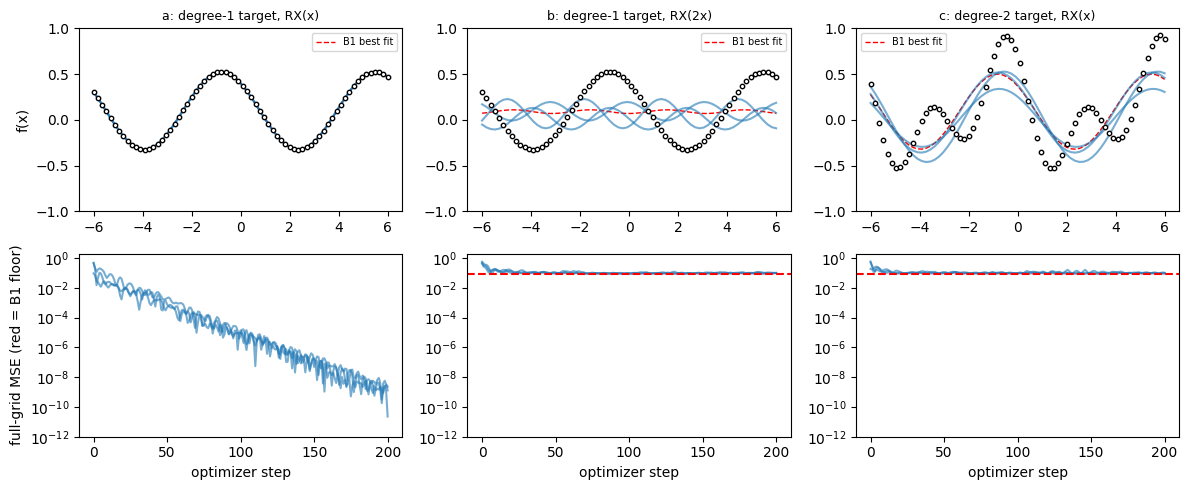

case                             B1 floor                       final MSE per seed  gap to floor
a: degree-1 target, RX(x)        2.11e-32                               [0. 0. 0.]  2.3e-11
b: degree-1 target, RX(2x)       8.97e-02             [0.100089 0.103116 0.096891]  7.2e-03
c: degree-2 target, RX(x)        8.97e-02             [0.098844 0.103419 0.090222]  5.1e-04
(live: 1 s, 3 seeds)


In [5]:
P0 = {"optimizer": "adam", "lr": 0.3, "batch_size": 25, "steps": 200, "init_high": 2 * np.pi, "full_batch": False}

def run_fit(kind, model_cfg, target_cfg, training, seeds, label=""):
    case = {"grid": GRID, "target": target_cfg, "training": training}
    x, y = build_dataset(case, DTYPE)
    freqs, scale = model_frequencies(model_cfg)
    floor = least_squares_oracle(x.numpy(), y.numpy(), freqs, scale)
    finals, preds, histories = [], [], []
    for seed in seeds:
        model = build_fit_model(kind, model_cfg, DTYPE)
        out = train_fit_model(model, case, seed, DEVICE, label)
        finals.append(out["final_mse"]); preds.append(out["predictions"].numpy()); histories.append(out["full_grid_mse"])
    return {"x": x.numpy(), "y": y.numpy(), "floor": floor, "finals": np.array(finals), "preds": preds, "hist": histories}

serial = lambda r, s=1.0: {"layout": "serial", "repetitions": r, "encoding_scaling": s, "readout": "z0"}
parallel = lambda r, s=1.0: {"layout": "parallel", "repetitions": r, "encoding_scaling": s, "ansatz": "strongly", "ansatz_layers": 3, "readout": "z0"}
LIVE_SEEDS = [0, 1, 2]

t0 = time.perf_counter()
fig3 = {
  "a: degree-1 target, RX(x)":      run_fit("quantum", serial(1, 1.0), TARGETS["Fig.3 degree 1"], P0, LIVE_SEEDS),
  "b: degree-1 target, RX(2x)":     run_fit("quantum", serial(1, 2.0), TARGETS["Fig.3 degree 1"], P0, LIVE_SEEDS),
  "c: degree-2 target, RX(x)":      run_fit("quantum", serial(1, 1.0), TARGETS["Fig.3 degree 2"], P0, LIVE_SEEDS),
}
fig, axes = plt.subplots(2, 3, figsize=(12, 5))
for col, (name, r) in enumerate(fig3.items()):
    axes[0, col].scatter(r["x"], r["y"], s=10, facecolor="white", edgecolor="black", zorder=3)
    axes[0, col].plot(r["x"], r["floor"]["predictions"], "r--", lw=1, label="B1 best fit")
    for p in r["preds"]: axes[0, col].plot(r["x"], p, color="tab:blue", alpha=0.6)
    axes[0, col].set_title(name, fontsize=9); axes[0, col].set_ylim(-1, 1); axes[0, col].legend(fontsize=7)
    for h in r["hist"]: axes[1, col].semilogy(h, color="tab:blue", alpha=0.6)
    axes[1, col].axhline(max(r["floor"]["mse"], 1e-32), color="r", ls="--"); axes[1, col].set_xlabel("optimizer step")
    axes[1, col].set_ylim(1e-12, 2)
axes[0, 0].set_ylabel("f(x)"); axes[1, 0].set_ylabel("full-grid MSE (red = B1 floor)")
plt.tight_layout(); plt.show()
print(f"{'case':30s} {'B1 floor':>10s} {'final MSE per seed':>40s}  gap to floor")
for name, r in fig3.items():
    print(f"{name:30s} {r['floor']['mse']:10.2e} {str(np.round(r['finals'], 6)):>40s}  {r['finals'].min() - r['floor']['mse']:.1e}")
print(f"(live: {time.perf_counter() - t0:.0f} s, {len(LIVE_SEEDS)} seeds)")

**Observation.** Row a fits to ~$10^{-8}$ or better; rows b and c stay at or above the floor of their frequency class (0.0897), and no seed goes below it.

**Inference.** A single encoding can produce only one frequency, and a mismatched scaling puts that frequency in the wrong place. The failure is *structural*: it sits exactly on the B1 floor, so no better optimiser could fix it.

**Remaining uncertainty.** The paper's Fig. 3 loss curves plateau at about 0.02, below this floor (0.045 even in the authors' $0.5\cdot$MSE). The quantity they plot cannot be the full-grid MSE of the plotted fit; its definition is unknown (documented in `README.md`, "Notes on the Paper").

**Claim impact.** C2 and C3: **reproduced** (trend; the paper gives no numbers).

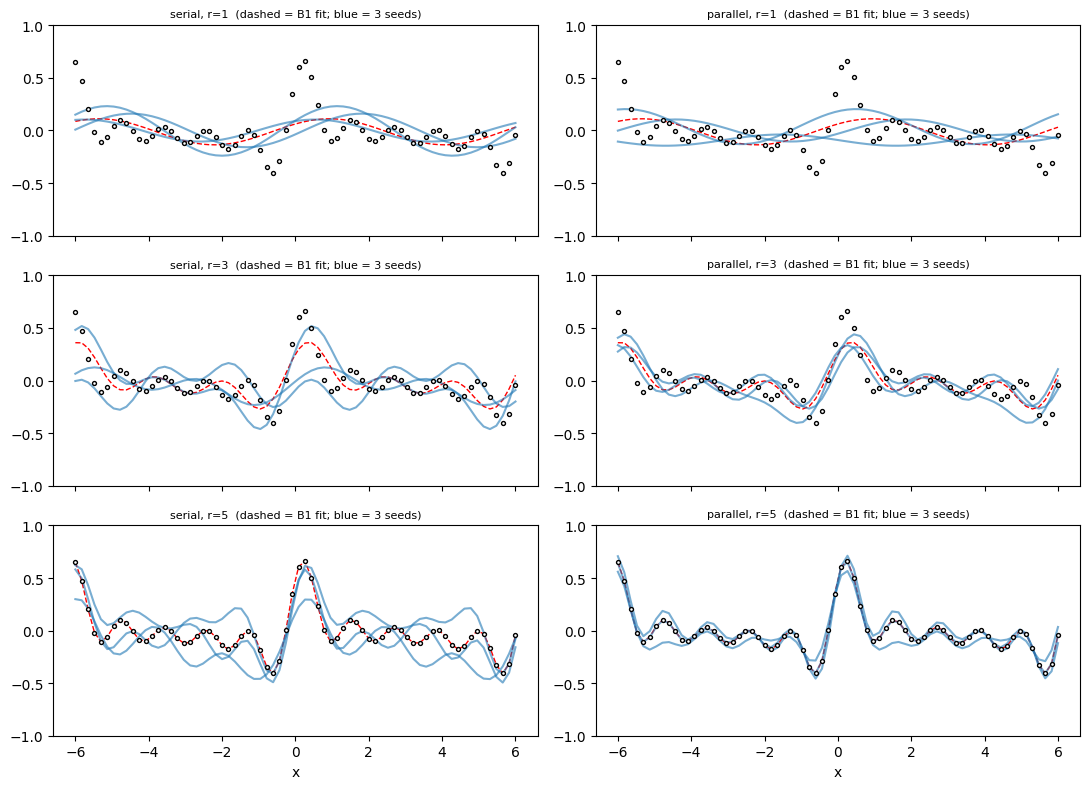

model           B1 floor   final MSE per seed   reached floor (gap<=1e-4)
serial r=1      3.57e-02   [3.7e-02 4.4e-02 4.3e-02]    0/3
parallel r=1    3.57e-02   [4.1e-02 4.1e-02 5.6e-02]    0/3
serial r=3      1.91e-02   [5.7e-02 3.3e-02 3.2e-02]    0/3
parallel r=3    1.91e-02   [2.1e-02 2.3e-02 3.2e-02]    0/3
serial r=5      1.91e-32   [2.2e-02 1.8e-02 4.4e-02]    0/3
parallel r=5    1.91e-32   [7.4e-03 2.5e-03 7.1e-05]    1/3
(live: 7 s)


In [6]:
t0 = time.perf_counter()
T4 = TARGETS["Fig.4 degree 5 (published scaling 1)"]
fig4 = {}
for r in (1, 3, 5):
    fig4[f"serial r={r}"] = run_fit("quantum", serial(r), T4, P0, LIVE_SEEDS)
    fig4[f"parallel r={r}"] = run_fit("quantum", parallel(r), T4, P0, LIVE_SEEDS)

fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharex=True)
for row, r in enumerate((1, 3, 5)):
    for col, layout in enumerate(("serial", "parallel")):
        res = fig4[f"{layout} r={r}"]; ax = axes[row, col]
        ax.scatter(res["x"], res["y"], s=8, facecolor="white", edgecolor="black", zorder=3)
        ax.plot(res["x"], res["floor"]["predictions"], "r--", lw=1)
        for p in res["preds"]: ax.plot(res["x"], p, color="tab:blue", alpha=0.6)
        ax.set_ylim(-1, 1); ax.set_title(f"{layout}, r={r}  (dashed = B1 fit; blue = {len(LIVE_SEEDS)} seeds)", fontsize=8)
for ax in axes[-1]: ax.set_xlabel("x")
plt.tight_layout(); plt.show()

print(f"{'model':14s} {'B1 floor':>9s}   final MSE per seed   reached floor (gap<=1e-4)")
for name, res in fig4.items():
    gaps = res["finals"] - res["floor"]["mse"]
    print(f"{name:14s} {res['floor']['mse']:9.2e}   {str(np.array2string(res['finals'], precision=1, formatter={'float_kind': lambda v: f'{v:.1e}'})):28s} {int((gaps <= 1e-4).sum())}/{len(gaps)}")
print(f"(live: {time.perf_counter() - t0:.0f} s)")

**Observation.** Error falls as $r$ grows, and the $r=5$ models approach the target, but with large spread between seeds; most live seeds at $r=5$ do not reach the floor in 200 steps.

**Inference.** The degree-$r$ spectrum claim holds directionally, and the models' *expressibility* is not the bottleneck at $r=5$ (B1 ≈ 0). Whether the fit is *reached* depends on training.

**Remaining uncertainty.** Three live seeds are far too few to estimate how often a seed succeeds; §7 and §10 use 6 and 20.

**Claim impact.** C4/C5 expressivity trend: **reproduced**; "almost perfect at $r=5$" is examined next.

## 7. Headline reproduction result (stored, 6 seeds, paper protocol)

Source runs: `outdir/run_20261028-100128` (Fig. 4, published scaling), summarised in `results/e2_fig4_summary.json`; `outdir/run_20261028-100040` (Fig. 3), `results/e1_fig3_summary.json`. Both ran the paper protocol on seeds 0–4 and 42, and passed the logging validator.

In [7]:
def load(name): return json.loads((RESULTS / name).read_text())
def pick(summary_json, label_prefix):
    return next(r for r in summary_json["runs"] if r["label"].startswith(label_prefix))

e1 = pick(load("e1_fig3_summary.json"), "E1 quantum")
e2 = pick(load("e2_fig4_summary.json"), "E2 quantum, s = 1 (published figure), 200 steps")

print("Fig. 3 (paper protocol, 6 seeds):")
print(f"  {'case':22s} {'mean ± std':>20s} {'B1 floor':>10s} {'seeds at floor':>14s}")
for s in e1["summary"]:
    print(f"  {s['case']:22s} {s['final_mse_mean']:10.2e} ± {s['final_mse_std']:.1e} {s['b1_mse']:10.2e} {round(s['success_fraction']*s['n_seeds']):>10d}/{s['n_seeds']}")
print("\nFig. 4 (published scaling, paper protocol, 6 seeds):")
print(f"  {'case':22s} {'mean ± std':>20s} {'B1 floor':>10s} {'seeds at floor':>14s}")
for s in e2["summary"]:
    print(f"  {s['case']:22s} {s['final_mse_mean']:10.2e} ± {s['final_mse_std']:.1e} {s['b1_mse']:10.2e} {round(s['success_fraction']*s['n_seeds']):>10d}/{s['n_seeds']}")

diag = load("e2_fig4_20seed_diagnostic.json")
print("\nFig. 4 diagnostic, 20 seeds (outdir/run_20261028-101252): seeds with final MSE <= 1e-3 ('visually near-perfect')")
for case, finals in diag["final_mse"].items():
    f = np.array(finals)
    print(f"  {case:22s} {int((f <= 1e-3).sum()):2d}/20   median {np.median(f):.1e}")

Fig. 3 (paper protocol, 6 seeds):
  case                             mean ± std   B1 floor seeds at floor
  fig3_row_a_degree1       4.24e-09 ± 6.8e-09   2.11e-32          6/6
  fig3_row_b_mismatch      1.03e-01 ± 1.3e-02   8.97e-02          0/6
  fig3_row_c_degree2       9.88e-02 ± 4.8e-03   8.97e-02          0/6

Fig. 4 (published scaling, paper protocol, 6 seeds):
  case                             mean ± std   B1 floor seeds at floor
  fig4s1_serial_r1         4.07e-02 ± 2.9e-03   3.57e-02          0/6
  fig4s1_serial_r3         3.74e-02 ± 1.1e-02   1.91e-02          0/6
  fig4s1_serial_r5         2.47e-02 ± 1.5e-02   1.91e-32          0/6
  fig4s1_parallel_r1       4.59e-02 ± 9.9e-03   3.57e-02          0/6
  fig4s1_parallel_r3       3.43e-02 ± 1.2e-02   1.91e-02          0/6
  fig4s1_parallel_r5       3.31e-03 ± 3.2e-03   1.91e-32          2/6

Fig. 4 diagnostic, 20 seeds (outdir/run_20261028-101252): seeds with final MSE <= 1e-3 ('visually near-perfect')
  fig4s1_serial_r1      

**Observation.** At $r=5$, under the paper's protocol, the mean final MSE is $2.5\times10^{-2}$ (serial) and $3.3\times10^{-3}$ (parallel), against a floor of zero. In 20 seeds, a near-perfect fit (MSE ≤ $10^{-3}$) occurs in 5/20 serial and 7/20 parallel runs. The paper reports no numbers and shows one run per panel.

**Inference.** The paper's *expressivity* statement is right (the target is exactly representable), but "fits almost perfectly" describes a favourable draw, roughly one in three or four, under the stated protocol.

**Remaining uncertainty.** The paper's "at most 200 steps" hides an unstated stopping rule, and its seed is unknown; an early-stopped favourable run would look like Fig. 4. We cannot recover that.

**Claim impact.** C4/C5: **partially supported**: reproduced as a trend, not as a reliable fit.

**Two more headline results, stored** (they carry claims C8 and C9, so their decisive numbers are shown here):
- **Fig. 5** (E3; `outdir/run_20261028-100212`, 100 random 4-qubit circuits per setting): variance of $\mathrm{Re}\,c_n$ and $\mathrm{Im}\,c_n$ per frequency; "0" means the coefficient vanishes in every draw.
- **Universality construction** (E5; `outdir/run_20261028-100221`): the paper's proof rebuilds target series exactly.

In [8]:
e3 = load("e3_fig5_summary.json")
print("Fig. 5: Var(Re c_n)+Var(Im c_n), 100 draws per setting (0 = vanishes in every draw); circuits with 4 qubits => predicted degree 4")
print(f"{'setting':14s}" + "".join(f"{'c_'+str(n):>10s}" for n in range(6)))
for s in e3["settings"]:
    cells = ["0" if e["fraction_zero"] == 1.0 else f"{e['var_total']:.1e}" for e in s["per_frequency"]]
    print(f"{s['label']:14s}" + "".join(f"{c:>10s}" for c in cells))
e5 = load("e5_universality_summary.json")
print(f"\nUniversality construction: worst reconstruction error over random truncated series (K<=8) = {e5['worst_exact_reconstruction_error']:.1e}; "
      f"square wave: worst relative gap between the measured RMS error and the exact Parseval truncation error = {e5['worst_relative_gap_to_parseval']:.1e}")

Fig. 5: Var(Re c_n)+Var(Im c_n), 100 draws per setting (0 = vanishes in every draw); circuits with 4 qubits => predicted degree 4
setting              c_0       c_1       c_2       c_3       c_4       c_5
strongly_l1      1.5e-02   7.9e-03   5.4e-03   1.6e-03         0         0
strongly_l5      1.5e-02   1.2e-02   7.8e-03   1.6e-03   1.9e-04         0
basic_l1               0   2.2e-02         0   7.9e-03         0         0
basic_l5               0   2.4e-02         0   8.2e-03         0         0
none_l0                0   0.0e+00         0         0         0         0

Universality construction: worst reconstruction error over random truncated series (K<=8) = 1.1e-14; square wave: worst relative gap between the measured RMS error and the exact Parseval truncation error = 3.9e-05


**Observation.** Circuit B (basic entangler) sets $c_0,c_2,c_4$ to zero in every draw; Circuit A (strongly entangling) has all frequencies up to the degree; $c_5\equiv0$ for every setting (degree 4); variance falls with order. $c_4$ is non-zero for Circuit A only at $l=5$. The universality construction reproduces any truncated series to $10^{-14}$, and its square-wave error equals the exact Fourier truncation error.

**Inference.** The ansatz type decides which coefficients exist, and depth changes the set for Circuit A, so "depth has little influence" (paper) is only roughly right; the construction in the proof is correct (with the factor $\tfrac12$ in Eq. 28 that the paper omits).

**Remaining uncertainty.** The paper's Fig. 5 settings were taken from the authors' notebook (4 qubits, $l\in\{1,5\}$).

**Claim impact.** C8: **reproduced** (qualitatively, with a depth nuance). C9: **reproduced exactly** (existence proof turned into a checked construction).

## 8. Fair baseline comparison

**What is compared.** The paper has no baseline. The claims concern expressivity, so the fair control is a classical model with *exactly the same frequency set* (B2: $a_0+\sum_{n\le D}(a_n\cos nx+b_n\sin nx)$, $2D+1$ coefficients), plus the closed-form floor B1. Fairness, dimension by dimension:

| Dimension | Quantum models vs B2 | Matched? |
|---|---|---|
| Information and inputs | same target, same 70-point grid, same scaling | **Yes** |
| Frequency set (capacity relevant to the claim) | $\{1..D\}$ for both | **Yes** |
| Parameter count | 18–123 angles vs $2D+1$ coefficients | **No**, reported, deliberately not matched |
| Training data | the same 70 points (no split) | **Yes** |
| Optimisation steps and optimiser | same optimiser, steps, batch sampler and seeds per protocol | **Yes** |
| Tuning budget | none for any model | **Yes** (none) |
| Compute and wall time | not matched: B2 is linear, 2–8 s per run vs 20–140 s for the circuits | **No**, reported |
| Evaluation protocol | same full-grid MSE and the same B1-based success rule | **Yes** |
| Initialisation | B2 comes in two variants (uniform $U[0,2\pi)$ like the circuits, and zero like the trainable readouts); both reported | **Partly**, disclosed |

**Live cell:** B2 on the Fig. 4 target at degrees 4, 5 under P0 (paper protocol) and a non-paper full-batch protocol P2, for both initialisations, 3 seeds.

In [9]:
def b2(degree, init): return {"layout": "serial", "repetitions": degree, "encoding_scaling": 1.0, "readout": "z0", "coefficient_init": init}
P2 = {"optimizer": "adam", "lr": 0.05, "batch_size": 25, "steps": 1000, "init_high": 2 * np.pi, "full_batch": True}
t0 = time.perf_counter()
print(f"{'degree':>6s} {'init':8s} {'protocol':10s} {'B1 floor':>9s} {'final MSE per seed':>44s}  at floor")
for degree in (4, 5):
    for init in ("uniform", "zero"):
        for pname, proto in (("P0 (paper)", P0), ("P2 (full)", P2)):
            res = run_fit("fourier_classical", b2(degree, init), T4, proto, LIVE_SEEDS)
            gaps = res["finals"] - res["floor"]["mse"]
            print(f"{degree:6d} {init:8s} {pname:10s} {res['floor']['mse']:9.1e} {np.array2string(res['finals'], formatter={'float_kind': lambda v: f'{v:.1e}'}):>44s}  {int((gaps <= 1e-4).sum())}/{len(gaps)}")
print(f"(live: {time.perf_counter() - t0:.0f} s)")

degree init     protocol    B1 floor                           final MSE per seed  at floor
     4 uniform  P0 (paper)   9.9e-03                    [1.1e-02 1.1e-02 1.0e-02]  0/3


     4 uniform  P2 (full)    9.9e-03                    [9.9e-03 9.9e-03 9.9e-03]  3/3
     4 zero     P0 (paper)   9.9e-03                    [2.4e-02 2.3e-02 2.7e-02]  0/3


     4 zero     P2 (full)    9.9e-03                    [9.9e-03 9.9e-03 9.9e-03]  3/3
     5 uniform  P0 (paper)   1.9e-32                    [8.7e-08 7.2e-08 5.4e-08]  3/3


     5 uniform  P2 (full)    1.9e-32                    [4.7e-33 4.2e-33 5.9e-33]  3/3
     5 zero     P0 (paper)   1.9e-32                    [2.9e-04 1.1e-02 1.3e-02]  0/3


     5 zero     P2 (full)    1.9e-32                    [4.6e-33 4.6e-33 4.6e-33]  3/3
(live: 2 s)


**Observation.** At degree 4 the floor is positive (0.0099) and the classical model can only reach it, which it does under the full-batch protocol P2 but not under P0. At degree 5 the floor is zero and it is reached **only under some protocol-and-initialisation combinations**: under P0 the uniform initialisation succeeds while the zero initialisation does not, and under P2 both succeed.

**Inference.** Even the minimal linear model of the class is protocol-sensitive. The quantum circuit's unreliability under P0 therefore cannot be attributed to the circuit alone.

**Remaining uncertainty.** Three live seeds; the stored 6-seed table is in §10.

**Claim impact.** The matched classical baseline **does not outperform** the quantum model on expressivity (same ceilings) and is **not** a more reliable trainer under the paper's protocol. No quantum advantage is claimed.

## 9. Controls and ablations

Three credible alternative explanations for "the r=5 fit is unreliable":

| Alternative | Control | Result (stored) |
|---|---|---|
| The target is not expressible | B1 floor at degree 5 | floor ≈ $10^{-32}$: expressible (§2) |
| The training protocol, not the circuit, is the problem | Full batch / smaller lr / L-BFGS, for qubit **and** classical models | §10: every expressible model reaches the floor under adequate protocols |
| The caption's scaling matters | Run both scaling 1 (published) and scaling 2 (caption) | same conclusions (below) |

**Caption versus figure.** The caption writes the target as $e^{2inx}$ (scaling 2). Reading the paper's Fig. 4 pixel positions, the plotted target has one large peak just left of $x=0$ and $f(6)\approx+0.65$, which matches only scaling 1 (the authors' notebook). Both are run; below is the stored comparison.

case                  scaling 1 mean  scaling 2 mean   (paper protocol, 6 seeds)
serial_r1                   4.07e-02        3.88e-02
serial_r3                   3.74e-02        3.71e-02
serial_r5                   2.47e-02        2.88e-02
parallel_r1                 4.59e-02        4.19e-02
parallel_r3                 3.43e-02        3.40e-02
parallel_r5                 3.31e-03        1.73e-03


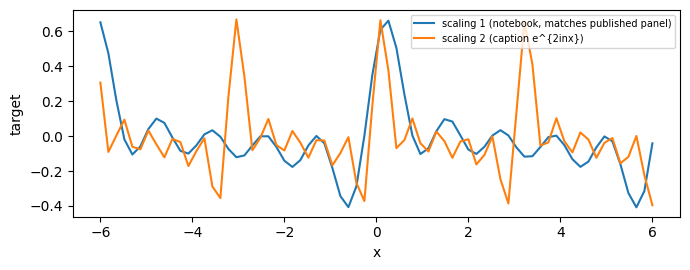

In [10]:
s1 = pick(load("e2_fig4_summary.json"), "E2 quantum, s = 1 (published figure), 200 steps")
s2 = pick(load("e2_fig4_summary.json"), "E2 quantum, s = 2 (caption), 200 steps")
print(f"{'case':20s} {'scaling 1 mean':>15s} {'scaling 2 mean':>15s}   (paper protocol, 6 seeds)")
for a, b in zip(s1["summary"], s2["summary"]):
    print(f"{a['case'].replace('fig4s1_', ''):20s} {a['final_mse_mean']:15.2e} {b['final_mse_mean']:15.2e}")

x = np.linspace(-6, 6, 70)
def tgt(sign, s, c): return sum((c*np.exp(1j*sign*s*n*x) + np.conj(c)*np.exp(-1j*sign*s*n*x)).real for n in range(1, 6))
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(x, tgt(+1, 1, 0.05-0.05j), label="scaling 1 (notebook, matches published panel)")
ax.plot(x, tgt(+1, 2, 0.05-0.05j), label="scaling 2 (caption e^{2inx})")
ax.set_xlabel("x"); ax.set_ylabel("target"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

**Observation.** The two scalings give the same error pattern across $r$ (both targets have degree 5 in their own frequency units); the plotted targets differ by oscillation count and peak positions.

**Inference.** The caption/figure disagreement is a presentation error that does not affect any conclusion.

**Remaining uncertainty.** None material.

**Claim impact.** None; the discrepancy is documented.

## 10. Robustness and uncertainty (stored)

Per-protocol results for the degree-5 target: how many of 6 seeds reach the B1 floor (MSE − floor ≤ $10^{-4}$), for the classical baseline (both initialisations), the qubit models with the paper's observable and with a trainable observable, under the paper's protocol P0 and four non-paper protocols. Source: `results/phase5_comparison.json`, `results/phase5_extensions.json` (from `utils/compare_phase5.py`, 130 and 73 rows; every run validated). Protocols: P1 full-batch lr 0.3, P2 lr 0.05, P3 lr 0.01 (1000 steps); P4 cosine-decayed Adam; P5 L-BFGS.

seeds reaching the B1 floor, of 6   P0 (paper)          P1          P2          P3          P4          P5
B2 classical, uniform init                 6/6         6/6         6/6         0/6         6/6         6/6
B2 classical, zero init                    0/6         6/6         6/6         6/6         6/6         6/6
qubit serial, <Z0>                         0/6         2/6         5/6         1/6         3/6         6/6
qubit serial, trainable obs.               0/6         1/6         6/6         6/6         6/6         6/6
qubit parallel, <Z0>                       2/6         5/6         6/6         6/6         6/6         6/6
qubit parallel, trainable obs.             0/6         6/6         6/6         6/6         6/6         6/6


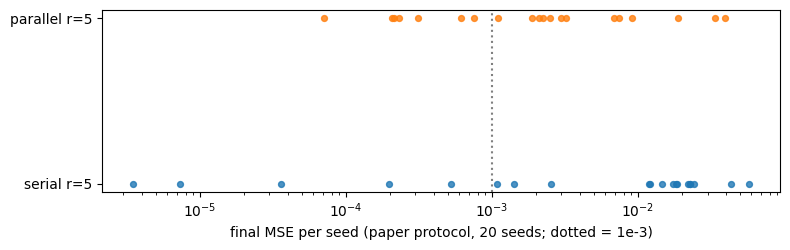

In [11]:
main = load("phase5_comparison.json")["rows"]; ext = load("phase5_extensions.json")["rows"]
def cell(rows, group, protocol, pred):
    sel = [r for r in rows if r["group"] == group and r["protocol"] == protocol and r["degree"] == 5 and pred(r)]
    if not sel: return "—"
    r = sel[0]; return f"{r['success_count']}/{r['expected_runs']}"
systems = [
  ("B2 classical, uniform init", lambda r: r["modality"] == "classical" and "uniform" in r["role"]),
  ("B2 classical, zero init",    lambda r: r["modality"] == "classical" and "zero" in r["role"]),
  ("qubit serial, <Z0>",         lambda r: r["modality"] == "qubit" and "serial" in r["case"] and r["readout"] == "z0"),
  ("qubit serial, trainable obs.", lambda r: r["modality"] == "qubit" and "serial" in r["case"] and r["readout"] == "trainable_linear"),
  ("qubit parallel, <Z0>",       lambda r: r["modality"] == "qubit" and "parallel" in r["case"] and r["readout"] == "z0"),
  ("qubit parallel, trainable obs.", lambda r: r["modality"] == "qubit" and "parallel" in r["case"] and r["readout"] == "trainable_linear"),
]
protocols = [("P0 (paper)", main, "G1", "P0"), ("P1", main, "G1", "P1"), ("P2", main, "G1", "P2"), ("P3", main, "G1", "P3"), ("P4", ext, "X3", "P4"), ("P5", ext, "X3", "P5")]
print(f"{'seeds reaching the B1 floor, of 6':34s}" + "".join(f"{p[0]:>12s}" for p in protocols))
for name, pred in systems:
    print(f"{name:34s}" + "".join(f"{cell(rows, g, pr, pred):>12s}" for _, rows, g, pr in protocols))

# Per-seed view for the paper protocol (20 seeds): individual results, not just counts.
diag = load("e2_fig4_20seed_diagnostic.json")
fig, ax = plt.subplots(figsize=(8, 2.6))
for i, case in enumerate(("fig4s1_serial_r5", "fig4s1_parallel_r5")):
    f = np.array(diag["final_mse"][case]); ax.scatter(f, np.full(len(f), i), s=18, alpha=0.8)
ax.axvline(1e-3, color="gray", ls=":"); ax.set_xscale("log"); ax.set_yticks([0, 1]); ax.set_yticklabels(["serial r=5", "parallel r=5"])
ax.set_xlabel("final MSE per seed (paper protocol, 20 seeds; dotted = 1e-3)"); plt.tight_layout(); plt.show()

**Observation.** Under the paper's protocol P0, every qubit model reaches the floor in at most 2/6 seeds; only the uniformly initialised classical baseline reaches it in 6/6, and its zero-initialised twin in 0/6. Under at least one non-paper protocol every system reaches it in 6/6 seeds (L-BFGS, P5, does so for all of them). No protocol is uniformly best: the uniform-init classical baseline fails at P3 (0/6) and qubit serial with $\langle Z_0\rangle$ is weak at P1 and P3 (2/6, 1/6). §11 adds the photonic models with a trainable readout.

**Inference.** The protocol, not the circuit, is the dominant obstacle: the paper's Fig. 4 shows an expressible fit, but its training recipe is a poor one for these models, whatever their nature.

**Remaining uncertainty.** 6 seeds per cell. Non-paper protocols were chosen to separate training from expressivity, never to improve a headline number: all protocols are shown, none selected. No statistical-superiority statement is made.

**Claim impact.** "Almost perfect fit at $r=5$": **supported as expressivity, not as a reliable outcome of the paper's protocol.** No quantum-over-classical advantage is visible anywhere.

## 11. Photonic extension (MerLin adaptation, not part of the reproduction)

**Status: `PARTIAL_MERLIN_TRANSLATION`.** The paper has no photonic model. The mapping: the encoding generator is the **photon number** on the encoded modes, so $n$ photons and $L$ encoding layers give degree $n\cdot L$. Circuit: $n$ single photons in $m$ modes, trainable MZI meshes between $L$ phase encodings of $x$, and a threshold-detector readout, either **fixed** ($2P(\text{no click in mode 0})-1$, the counterpart of the paper's $\langle Z\rangle$) or a **trainable linear readout** over click patterns. All results are noiseless MerLin 0.2.3 simulation (FOCK space, threshold detectors emulated exactly, exact autograd gradients, no shots), not hardware.

**Why FOCK and not MerLin's default UNBUNCHED:** UNBUNCHED is postselection with renormalisation, which makes the output non-band-limited; the live cell below shows it.

**Live cell 1: the spectrum transfers.** FFT support of random photonic circuits vs the prediction (FOCK), and the UNBUNCHED contrast.

In [12]:
import merlin as ml
from lib.photonic_merlin import build_photonic_model, photonic_positive_frequencies

def pcfg(n, m, modes, scales, layers, screens, readout, space="fock"):
    return {"layout": "photonic", "n_photons": n, "n_modes": m, "encoded_modes": modes, "mode_scales": scales, "encoding_layers": layers,
            "encoding_scaling": 1.0, "phase_screens": screens, "readout": readout, "computation_space": space}

def photonic_support(cfg, seeds=range(3), n_points=64):
    grid = torch.tensor(periodic_grid(n_points), dtype=DTYPE)
    union, stray = set(), 0.0
    pred = [0] + [f for f in photonic_positive_frequencies(cfg)] + [-f for f in photonic_positive_frequencies(cfg)]
    for s in seeds:
        m = build_photonic_model(cfg, DTYPE); m.reset_parameters(torch.Generator().manual_seed(s), 2 * np.pi)
        with torch.no_grad():
            cols = [*m.probabilities(grid).numpy().T, m(grid).numpy()]
        for col in cols:
            f, c = fourier_coefficients(col); union |= set(spectrum_support(f, c, 1e-9))
            stray = max(stray, float(np.abs(c[~np.isin(f, pred)]).max()) if (~np.isin(f, pred)).any() else 0.0)
    return sorted(union), sorted(set(pred)), stray

cases = [("1 photon, 2 modes", pcfg(1, 2, [0], [1.0], 1, False, "threshold_mode0")),
         ("3 photons, 4 modes", pcfg(3, 4, [0], [1.0], 1, False, "threshold_mode0")),
         ("2 photons, re-upload L=3", pcfg(2, 3, [0], [1.0], 3, False, "threshold_mode0")),
         ("2 photons, 2 of 4 modes encoded", pcfg(2, 4, [0, 1], [1.0, 1.0], 1, False, "threshold_mode0")),
         ("2 photons, ALL modes encoded", pcfg(2, 3, [0, 1, 2], [1.0] * 3, 1, False, "threshold_mode0")),
         ("1 photon, scales 1..5 on 5 modes", pcfg(1, 6, [1, 2, 3, 4, 5], [1., 2., 3., 4., 5.], 1, True, "trainable_linear"))]
print(f"{'FOCK model':36s} {'predicted degree':>16s} {'observed degree':>15s} {'stray coeff.':>12s}")
for name, cfg in cases:
    obs, pred, stray = photonic_support(cfg)
    print(f"{name:36s} {max(pred):16d} {max(obs):15d} {stray:12.1e}   {'OK' if obs == pred else 'MISMATCH'}")
    assert obs == pred

# UNBUNCHED contrast: same 2-photon circuit, collision-free outcomes renormalised.
import perceval as pcvl
def probe(space):
    c = pcvl.Circuit(3); c.add(0, pcvl.BS()); c.add(0, pcvl.PS(pcvl.P("px"))); c.add(1, pcvl.BS()); c.add(0, pcvl.BS())
    return ml.QuantumLayer(input_size=1, circuit=c, input_state=[1, 1, 0], n_photons=2, trainable_parameters=[],
                           input_parameters=["px"], computation_space=space, dtype=DTYPE)
g = torch.tensor(periodic_grid(256), dtype=DTYPE).unsqueeze(1)
with torch.no_grad():
    for name, space in (("FOCK", ml.ComputationSpace.FOCK), ("UNBUNCHED", ml.ComputationSpace.UNBUNCHED)):
        probs = probe(space)(g).numpy(); sup = set()
        for col in probs.T:
            f, c = fourier_coefficients(col); sup |= set(spectrum_support(f, c, 1e-9))
        print(f"{name:10s}: largest frequency in the output = {max(sup):3d}  (prediction for this circuit: 2)")

FOCK model                           predicted degree observed degree stray coeff.
1 photon, 2 modes                                   1               1      1.1e-16   OK
3 photons, 4 modes                                  3               3      1.2e-16   OK
2 photons, re-upload L=3                            6               6      2.3e-16   OK
2 photons, 2 of 4 modes encoded                     2               2      1.1e-16   OK
2 photons, ALL modes encoded                        0               0      1.4e-16   OK


1 photon, scales 1..5 on 5 modes                    5               5      5.6e-17   OK
FOCK      : largest frequency in the output =   2  (prediction for this circuit: 2)


UNBUNCHED : largest frequency in the output =  26  (prediction for this circuit: 2)


**Observation.** For FOCK, the support equals the photon-number prediction in every case (degree $n\cdot L$; encoding 2 of 4 modes adds nothing beyond $n$; encoding every mode is a global phase, i.e. constant). For UNBUNCHED the spectrum extends far beyond the prediction (frequency 26 against 2 for this circuit, at the $10^{-9}$ threshold).

**Inference.** The paper's theory transfers *exactly* to linear optics when the output is an expectation value; the resource is photons and re-uploading, not the number of encoded modes. MerLin's postselected default must not be analysed as a truncated Fourier series.

**Remaining uncertainty.** Noiseless, lossless, indistinguishable photons assumed; a real source changes the spectrum.

**Claim impact.** C1/C4 (spectrum) and C7 (a phase shifter's generator gives the full integer spectrum): **supported in the photonic adaptation** (stored: `results/merlin_spectrum_summary.md`, 9/9 checks).

**Live cell 2: the readout is what limits fits.** The Fig. 4 target with a degree-6 photonic model ($n=2$, $L=3$), fixed vs trainable readout, universal meshes (a trainable phase screen before each mesh, which the MerLin 0.2.3 mesh lacks), full-batch Adam, 2 seeds (stored: 6 seeds, L-BFGS 20 seeds).

fixed readout, universal mesh        B1 floor 2.0e-32   final MSE per seed [3.9e-03 2.0e-03]


trainable readout, universal mesh    B1 floor 2.0e-32   final MSE per seed [1.5e-07 5.1e-05]


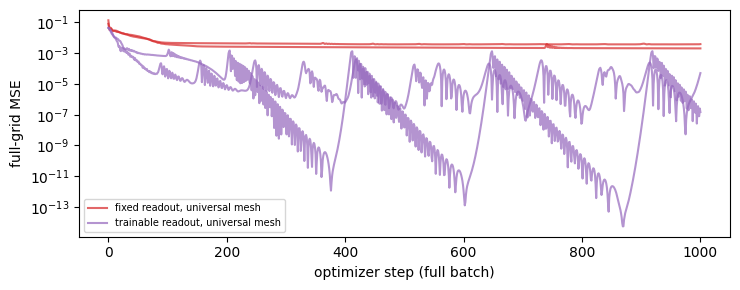

(live: 11 s)


In [13]:
t0 = time.perf_counter()
P2n = {"optimizer": "adam", "lr": 0.05, "batch_size": 25, "steps": 1000, "init_high": 2 * np.pi, "full_batch": True}
variants = {"fixed readout, universal mesh": pcfg(2, 3, [0], [1.0], 3, True, "threshold_mode0"),
            "trainable readout, universal mesh": pcfg(2, 3, [0], [1.0], 3, True, "trainable_linear")}
live = {}
for name, cfg in variants.items():
    live[name] = run_fit("photonic", cfg, T4, P2n, [0, 1])
    r = live[name]; print(f"{name:36s} B1 floor {r['floor']['mse']:.1e}   final MSE per seed {np.array2string(r['finals'], formatter={'float_kind': lambda v: f'{v:.1e}'})}")
fig, ax = plt.subplots(figsize=(7.5, 3))
for (name, r), color in zip(live.items(), ("tab:red", "tab:purple")):
    for h in r["hist"]: ax.semilogy(h, color=color, alpha=0.7, label=name if h is r["hist"][0] else None)
ax.set_xlabel("optimizer step (full batch)"); ax.set_ylabel("full-grid MSE"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()
print(f"(live: {time.perf_counter() - t0:.0f} s)")

In [14]:
# Stored: photonic universality test (one photon in m modes, phase k x on mode k, universal mesh, trainable readout) on a square wave.
uni = load("merlin_universality_summary.json")
p3 = next(r for r in uni["runs"] if "P3" in r["label"]); p0 = next(r for r in uni["runs"] if "P0" in r["label"])
print(f"{'K=m-1':>6s} {'B1 floor':>9s} {'P0 (paper) mean':>16s} {'P0 at floor':>12s} {'P3 mean':>10s} {'P3 at floor':>12s}   (square wave, 6 seeds; runs 20261028-160148 / -160227)")
for a, b in zip(p0["summary"], p3["summary"]):
    K = int(a["case"].split("_K")[1])
    print(f"{K:6d} {a['b1_mse']:9.4f} {a['final_mse_mean']:16.4f} {round(a['success_fraction']*6):>9d}/6 {b['final_mse_mean']:10.4f} {round(b['success_fraction']*6):>9d}/6")

 K=m-1  B1 floor  P0 (paper) mean  P0 at floor    P3 mean  P3 at floor   (square wave, 6 seeds; runs 20261028-160148 / -160227)
     1    0.1768           0.2087         0/6     0.1768         6/6
     2    0.1768           0.2063         0/6     0.1768         6/6
     3    0.0867           0.1269         0/6     0.0867         6/6
     4    0.0867           0.1511         0/6     0.0867         6/6
     5    0.0543           0.1056         0/6     0.0543         6/6
     6    0.0543           0.1352         0/6     0.0543         6/6
     7    0.0377           0.1783         0/6     0.0377         6/6


**Observation.** With a fixed readout, the photonic model plateaus between $2\times10^{-3}$ and $4\times10^{-3}$; with a trainable readout both seeds get within $10^{-4}$ of the floor (live, 2 seeds).

**Stored evidence** (6 seeds; 20 seeds for L-BFGS; `results/phase5_extensions.md`, `results/merlin_amendment_photonic_summary.md`, `results/merlin_universality_summary.md`): under L-BFGS with 20 seeds, qubit models with $\langle Z_0\rangle$ and the classical baseline reach the floor 20/20, while all three photonic fixed-readout models reach it 0/20, with two different circuits stalling at the same best value (1.59e-3). With universal meshes and a trainable readout, photonic models reach the target 6/6 under full-batch protocols (P2/P3) and L-BFGS. A one-photon model in $m=2..8$ modes with phase $k\,x$ on mode $k$ (a universal Hamiltonian family), universal mesh and trainable readout reaches the best degree-$K$ approximation of a square wave in 6/6 seeds for every $K=1..7$ (stored).

**Inference.**
- The fixed single-mode observable, not the optimiser or the mesh, is the limit of the photonic model (strong evidence: stronger optimiser, universal mesh and a different circuit all leave the same plateau).
- The universality theorem holds photonically in the single-photon setting that satisfies its assumptions. A single photon is classically simulable, so this tests the theorem, not quantum value.
- Multi-photon multi-scale encodings are more parameter-efficient than the single-photon construction for the same degree (3 photons in 4 modes, ~40 parameters, versus 10 modes and 200 parameters at degree 9), at slightly lower per-seed reliability.

**Remaining uncertainty.** The plateau is evidence of a model-class limit, not a proof. Trainable readouts add classical parameters and change the model class relative to the paper's fixed $\langle Z\rangle$; qubit and classical models were given the same readout class for the comparison. All photonic results are noiseless simulation; MerLin 0.2.3 defects found along the way (non-universal mesh, multi-call encoding scales, UNBUNCHED semantics) are in `ACTION_REQUIRED_SEND_TO_MERLIN_TEAM.md`.

**Claim impact.** The photonic adaptation shows the paper's mechanism is meaningful in photonics; it yields **no quantum or photonic advantage** over the qubit or classical models (with fixed observables qubit > photonic; with trainable observables, tied).


## Deviations, reductions and their likely impact

Everything that differs from the paper or from a full-scale run, in one place.

| Deviation / reduction | Why | Likely impact on conclusions |
|---|---|---|
| Circuits re-implemented in a torch statevector simulator instead of PennyLane | PennyLane's 2020 API does not run on current versions; conventions copied, verified against a dense-matrix build and parameter shift (`tests/test_circuits.py`) | None on spectrum claims; could shift small details of Figs. 4–5 only |
| Settings the paper omits taken from the authors' notebook (grid `linspace(-6, 6, 70)`, angles $U[0,2\pi)$, lr 0.3 for Fig. 3, batch 25 with replacement) | Paper does not state them | Low; the claims concern function classes. The paper's Fig. 3 loss curves span ~100 steps, we use 200: more steps cannot lower the floor-limited rows b and c |
| Exactly 200 steps, no early stopping | "At most 200 steps" has an unrecoverable stopping rule | Could explain why the paper's Fig. 4 looks better than a typical seed |
| Fig. 4 with input scaling 1 (published panel) as primary; caption's scaling 2 also run | Caption and figure disagree (§9) | None; both give the same conclusions |
| Plain MSE instead of the notebook's $0.5\cdot$MSE | Adam is invariant to a constant loss scale (apart from $\epsilon$) | Negligible |
| 6 seeds (3 in live cells, 20 in two diagnostics) instead of the paper's single run | Uncertainty must be shown | Makes the Fig. 4 reliability finding possible |
| No paper numbers exist for Figs. 3–5 | The paper reports none | Every paper comparison is trend-level |
| Non-paper training protocols P1–P5 | To separate training from expressivity | Labelled as controls; never replace the paper protocol |
| Photonic section: MerLin 0.2.3 simulation (FOCK, threshold detectors emulated), noiseless, no shots, universal meshes and trainable readouts added | The paper has no photonic model; MerLin's default `UNBUNCHED` is not threshold detection; its mesh lacks input-side phases | An adaptation, not a reproduction; no hardware claim; trainable readouts change the model class (stated in §11) |
| Live cells smaller than stored runs; stored runs loaded from `results/*.json` | Keep the notebook interactive (~40 s) | Live cells show the mechanism; stored 6/20-seed runs carry the statistics |


## 12. Claim-level conclusion

Evidence sections in parentheses.

### 1. What reproduced
- The spectrum theory, exactly: spectrum fixed by the encoding generator; $\{-r..r\}$ for serial and parallel repetition; the size bound; the universality construction (§4; stored E4, E5).
- Fig. 3: one encoding fits degree 1 and cannot fit a mismatched or degree-2 target, structurally (§6, §7).
- Fig. 5 trends: structural zeros by ansatz, variance falling with order, with the nuance that depth changes which coefficients appear (stored: `results/e3_fig5_summary.md`).
- The photonic spectrum mapping, exactly (§11).

### 2. What did not reproduce
- "The degree-5 target is fit almost perfectly at $r=5$" as a *reliable* outcome of the paper's protocol: 5/20 serial and 7/20 parallel seeds (§7).

### 3. What remains unresolved
- The paper's stopping rule and seed (so how Fig. 4 was obtained), and the quantity plotted on Fig. 3's loss axis (§6, §7).
- Whether the fixed-readout photonic plateau is a proven limit rather than strongly evidenced (§11).

### 4. What was not attempted
- Hardware runs; photon loss, distinguishability and finite shots; a held-out-data task (so no generalisation claim); the paper's Section V design guidance (interpretation); multivariate and non-integer photonic cases (share the same mechanism as the checked spectrum).

### 5. Reproduction verdict
- **Theory: reproduced exactly.** **Training figures: partially supported**, with 6 seeds (20 for diagnostics): trends reproduced; reliability claim not. A frequency-matched classical baseline hits the same ceilings and is equally protocol-sensitive (§8–§10); no quantum advantage is claimed by the paper or found.
- Separated outcomes: the software executes (§1–§6); the method solves the task (expressively, §2/§7; reliably only under adequate protocols, §10); the paper's metric reproduces (no paper numbers exist; trends do); the paper's explanation survives controls (expressivity yes; "fits reliably" no, §9–§10); the method beats a fair baseline (no, §8).

### 6. Extension (photonic) verdict
- `PARTIAL_MERLIN_TRANSLATION`: the spectrum theory transfers exactly; photonic models reach the targets only with universal meshes and a trainable observable; the universality theorem holds in a single-photon setting (a theorem test); no advantage. Noiseless simulation only (§11).

### Limitations
- Synthetic one-dimensional targets, no held-out split; 6 seeds (3 in live cells, 20 in two diagnostics); the paper reports no numbers, so every comparison with it is trend-level; non-paper protocols are labelled and never replace the paper protocol; stored full runs live in `outdir/` and are summarised in `results/`; live cells are smaller than stored runs (3 seeds, same protocols).

In [15]:
import importlib.metadata as md_, platform, os, subprocess
def git(*a):
    try: return subprocess.check_output(["git", "-C", str(REPO_ROOT), *a], text=True).strip()
    except Exception: return "unavailable"
print(f"notebook wall-clock so far: {time.perf_counter() - NOTEBOOK_START:.0f} s (limit 10 min)")
print("execution: CPU only (torch device =", DEVICE, f", {os.cpu_count()} cores)")
print("environment: Python", platform.python_version(), "|", platform.system(), platform.machine(), "| venv:", sys.prefix != sys.base_prefix)
print("packages: torch", torch.__version__, "| numpy", np.__version__, "| matplotlib", md_.version("matplotlib"),
      "| merlinquantum", md_.version("merlinquantum"), "| perceval-quandela", md_.version("perceval-quandela"))
print("code revision:", git("rev-parse", "--short", "HEAD"), "(paper folder untracked: dirty =", bool(git("status", "--porcelain")), ")")
print("seeds: live cells", LIVE_SEEDS, "| stored runs 0-4 and 42 (6 seeds), 0-19 (diagnostics)")
print("stored-result sources: results/*.json (from validated runs; see LOG.md for run directories, commands and code state)")

notebook wall-clock so far: 22 s (limit 10 min)
execution: CPU only (torch device = cpu , 10 cores)
environment: Python 3.12.7 | Darwin arm64 | venv: True
packages: torch 2.4.1 | numpy 2.3.5 | matplotlib 3.10.3 | merlinquantum 0.2.3 | perceval-quandela 1.0.0
code revision: e7beb6a (paper folder untracked: dirty = True )
seeds: live cells [0, 1, 2] | stored runs 0-4 and 42 (6 seeds), 0-19 (diagnostics)
stored-result sources: results/*.json (from validated runs; see LOG.md for run directories, commands and code state)
